# Fase 1: Análisis Exploratorio de Datos (EDA) - MiBici Guadalajara
**Materia:** Operación con ML (TC5061)  
**Equipo:** 19  
**Datos:** viajes de mayo de 2024 del portal de datos abiertos de MiBici (410,806 registros) y catálogo vigente de estaciones.  
**Objetivo:** Explorar patrones temporales, demográficos y espaciales del sistema MiBici para sustentar la formulación del problema de predicción de demanda horaria por estación y rebalanceo de estaciones.

El cuaderno reutiliza las clases del paquete `src` (`MiBiciDataCleaner` y `MiBiciFeatureEngineer`) para que los números y figuras coincidan exactamente con los que produce el pipeline (`make pipeline`).

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Añadir directorio raíz del proyecto para importar módulos de src
sys.path.append('..')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 30)
%matplotlib inline

print(f'pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}')

pandas 3.1.0 | numpy 2.4.6 | seaborn 0.13.2


## 1. Carga de Datos Brutos y Nomenclatura de Estaciones

In [2]:
df_trips = pd.read_csv('../data/raw/viajes_raw.csv')
df_stations = pd.read_csv('../data/raw/nomenclatura_estaciones.csv')
print(f'Dimensiones de viajes brutos: {df_trips.shape}')
print(f'Estaciones registradas en catálogo: {len(df_stations)}')
df_trips.head()

Dimensiones de viajes brutos: (410806, 8)
Estaciones registradas en catálogo: 484


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,33617601,1010367,M,1990.0,2024-05-01 00:01:35,2024-05-01 00:09:08,196,49
1,33617605,2240043,M,1994.0,2024-05-01 00:02:00,2024-05-01 00:22:20,174,229
2,33617607,2762155,M,2003.0,2024-05-01 00:02:29,2024-05-01 00:02:46,33,33
3,33617610,1452765,M,1988.0,2024-05-01 00:02:57,2024-05-01 00:14:42,30,3
4,33617611,2431176,M,2000.0,2024-05-01 00:03:17,2024-05-01 00:10:59,196,177


## 2. Inspección de Calidad de Datos (Nulos, Tipos y Anomalías)

Antes de aplicar reglas de limpieza se revisan nulos, tipos de dato, duplicados y los rangos de duración y año de nacimiento tal como vienen en el archivo original.

In [3]:
print('--- Resumen de Valores Nulos ---')
print(df_trips.isnull().sum())
print('\n--- Tipos de Datos Originales ---')
print(df_trips.dtypes)

--- Resumen de Valores Nulos ---
Viaje_Id                0
Usuario_Id              0
Genero               2494
Año_de_nacimiento     254
Inicio_del_viaje        0
Fin_del_viaje           0
Origen_Id               0
Destino_Id              0
dtype: int64

--- Tipos de Datos Originales ---
Viaje_Id               int64
Usuario_Id             int64
Genero                   str
Año_de_nacimiento    float64
Inicio_del_viaje         str
Fin_del_viaje            str
Origen_Id              int64
Destino_Id             int64
dtype: object


### 2.1 Duplicados y rangos antes de limpiar

In [4]:
print(f"Duplicados por Viaje_Id: {df_trips.duplicated(subset=['Viaje_Id']).sum()}")
print(f"Filas completamente duplicadas: {df_trips.duplicated().sum()}")

inicio = pd.to_datetime(df_trips['Inicio_del_viaje'], errors='coerce')
fin = pd.to_datetime(df_trips['Fin_del_viaje'], errors='coerce')
duracion_min = (fin - inicio).dt.total_seconds() / 60.0

print(f"\nPeriodo cubierto: {inicio.min()} a {inicio.max()}")
print(f"Fechas no parseables: {inicio.isna().sum() + fin.isna().sum()}")

rangos = pd.DataFrame({
    'duracion_minutos': duracion_min.describe(),
    'Año_de_nacimiento': df_trips['Año_de_nacimiento'].describe(),
}).round(2)
rangos

Duplicados por Viaje_Id: 0
Filas completamente duplicadas: 0



Periodo cubierto: 2024-05-01 00:01:35 a 2024-05-31 23:59:53
Fechas no parseables: 0


,duracion_minutos,Año_de_nacimiento
count,410806.00,410552.00
mean,10.76,1989.77
std,8.56,17.80
min,0.00,200.00
25%,5.60,1984.00
50%,9.27,1993.00
75%,14.52,1998.00
max,1093.30,2023.00


In [5]:
# Conteo de casos fuera de las reglas de negocio que aplicará el cleaner
print(f"Duraciones no positivas (<= 0 s): {(duracion_min <= 0).sum()}")
print(f"Viajes ultracortos (< 1 min): {((duracion_min > 0) & (duracion_min < 1)).sum()}")
print(f"Viajes excesivos (> 120 min): {(duracion_min > 120).sum()}")
print(f"Años de nacimiento fuera de [1934, 2010]: {((df_trips['Año_de_nacimiento'] < 1934) | (df_trips['Año_de_nacimiento'] > 2010)).sum()}")
print(f"Viajes con estación de origen o destino fuera del catálogo: "
      f"{(~df_trips['Origen_Id'].isin(df_stations['id']) | ~df_trips['Destino_Id'].isin(df_stations['id'])).sum()}")

Duraciones no positivas (<= 0 s): 921
Viajes ultracortos (< 1 min): 14033
Viajes excesivos (> 120 min): 96
Años de nacimiento fuera de [1934, 2010]: 86
Viajes con estación de origen o destino fuera del catálogo: 0


## 3. Integración con el Módulo POO de Limpieza (Data Engineer)
Para garantizar reproducibilidad y calidad de software, la lógica de limpieza fue refactorizada en la clase `MiBiciDataCleaner` (`src/data/cleaner.py`). Las reglas son: eliminar duplicados por `Viaje_Id`, descartar duraciones no positivas, menores a 1 minuto y mayores a 120 minutos, conservar solo estaciones del catálogo y filtrar edades fuera del rango de 14 a 90 años.

In [6]:
from src.data.cleaner import MiBiciDataCleaner

cleaner = MiBiciDataCleaner(
    raw_trips_path='../data/raw/viajes_raw.csv',
    raw_stations_path='../data/raw/nomenclatura_estaciones.csv',
    output_dir='../data/interim'
)
df_clean, clean_path = cleaner.clean()
df_clean.describe()

2026/10/25 22:39:15 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/ericksiller/Documents/Proyectos/proyecto-bici/.venv/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


=== Iniciando Limpieza y Validación de Datos (Data Engineer / ML Engineer) ===


Dataset limpio guardado en: ../data/interim/viajes_cleaned.csv
Filas iniciales: 410806 -> Filas limpias: 395672 (Retención: 96.32%)


,Viaje_Id,Usuario_Id,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,duracion_segundos,duracion_minutos,Edad
count,3.956720e+05,3.956720e+05,395672.000000,395672,395672,395672.000000,395672.000000,395672.000000,395672.000000,395672.000000
mean,3.385907e+07,1.717962e+06,1989.852807,2024-05-16 18:17:38.892376,2024-05-16 18:28:44.525146,150.770732,152.702365,665.632772,11.093880,34.147193
min,3.361760e+07,1.020000e+02,1939.000000,2024-05-01 00:01:35,2024-05-01 00:05:31,2.000000,2.000000,60.000000,1.000000,16.000000
25%,3.373756e+07,5.365740e+05,1984.000000,2024-05-08 20:01:08,2024-05-08 20:12:43,51.000000,51.000000,358.000000,5.966667,26.000000
50%,3.385957e+07,1.617560e+06,1993.000000,2024-05-16 15:27:29.500000,2024-05-16 15:38:47,154.000000,154.000000,574.000000,9.566667,31.000000
75%,3.398032e+07,2.666056e+06,1998.000000,2024-05-24 06:45:55.250000,2024-05-24 06:54:01,253.000000,257.000000,886.000000,14.766667,40.000000
max,3.409926e+07,4.035675e+06,2008.000000,2024-05-31 23:59:53,2024-06-01 00:33:17,388.000000,388.000000,7096.000000,118.266667,85.000000
std,1.393955e+05,1.214247e+06,10.678110,NaN,NaN,108.744436,112.193905,413.586038,6.893101,10.678110


### 3.1 Métricas de la limpieza

In [7]:
metricas = (
    pd.Series(cleaner.metrics, name='valor')
    .rename_axis('metrica')
    .reset_index()
)
metricas

,metrica,valor
0,initial_rows,410806.00
1,final_rows,395672.00
2,total_dropped_rows,15134.00
3,dropped_duplicates,0.00
4,dropped_negative_durations,921.00
5,dropped_short_trips,14033.00
6,dropped_excessive_durations,96.00
7,dropped_invalid_stations,0.00
8,dropped_invalid_ages,84.00
9,retention_rate_pct,96.32


## 4. Análisis Exploratorio y Extracción de Características (Data Scientist)
Refactorizado en `MiBiciFeatureEngineer` (`src/features/engineer.py`), donde se construyen variables cíclicas y de rezago para el modelo de demanda horaria. La clase también exporta las cinco figuras base del EDA a `reports/figures`.

In [8]:
from src.features.engineer import MiBiciFeatureEngineer

engineer = MiBiciFeatureEngineer(
    cleaned_trips_path='../data/interim/viajes_cleaned.csv',
    stations_path='../data/raw/nomenclatura_estaciones.csv',
    output_dir='../data/processed',
    figures_dir='../reports/figures'
)
df_features, feat_path = engineer.build_features()
print(f'Dimensiones del dataset final con características: {df_features.shape}')
print(f"Estaciones activas en el mes: {df_features['Origen_Id'].nunique()}")
df_features.head(10)

=== Iniciando Ingeniería de Características (Data Scientist / ML Engineer) ===
--- Generando gráficas del Análisis Exploratorio (Data Scientist) ---


5 Gráficas del EDA exportadas exitosamente a: ../reports/figures


Dataset con características generado en: ../data/processed/mibici_hourly_demand.csv
Dimensiones finales: 267840 filas, 16 columnas
Dimensiones del dataset final con características: (267840, 16)
Estaciones activas en el mes: 360


,Origen_Id,fecha_hora,demand_count,hour,day_of_week,is_weekend,month,sin_hour,cos_hour,sin_dayofweek,cos_dayofweek,latitude,longitude,capacity,demand_lag_1h,demand_lag_24h
0,2,2024-05-01 00:00:00,0,0,2,0,5,0.000000,1.000000e+00,0.974928,-0.222521,20.666378,-103.34882,15,0.0,0.0
1,2,2024-05-01 01:00:00,0,1,2,0,5,0.258819,9.659258e-01,0.974928,-0.222521,20.666378,-103.34882,15,0.0,0.0
2,2,2024-05-01 02:00:00,0,2,2,0,5,0.500000,8.660254e-01,0.974928,-0.222521,20.666378,-103.34882,15,0.0,0.0
3,2,2024-05-01 03:00:00,0,3,2,0,5,0.707107,7.071068e-01,0.974928,-0.222521,20.666378,-103.34882,15,0.0,0.0
4,2,2024-05-01 04:00:00,0,4,2,0,5,0.866025,5.000000e-01,0.974928,-0.222521,20.666378,-103.34882,15,0.0,0.0
5,2,2024-05-01 05:00:00,0,5,2,0,5,0.965926,2.588190e-01,0.974928,-0.222521,20.666378,-103.34882,15,0.0,0.0
6,2,2024-05-01 06:00:00,0,6,2,0,5,1.000000,6.123234e-17,0.974928,-0.222521,20.666378,-103.34882,15,0.0,0.0
7,2,2024-05-01 07:00:00,0,7,2,0,5,0.965926,-2.588190e-01,0.974928,-0.222521,20.666378,-103.34882,15,0.0,0.0
8,2,2024-05-01 08:00:00,1,8,2,0,5,0.866025,-5.000000e-01,0.974928,-0.222521,20.666378,-103.34882,15,0.0,0.0
9,2,2024-05-01 09:00:00,3,9,2,0,5,0.707107,-7.071068e-01,0.974928,-0.222521,20.666378,-103.34882,15,1.0,0.0


## 5. Figuras del EDA generadas por el pipeline

Las cinco gráficas se muestran tal como las genera `MiBiciFeatureEngineer`, de modo que son las mismas que aparecen en el reporte.

### 5.1 Distribución horaria de viajes

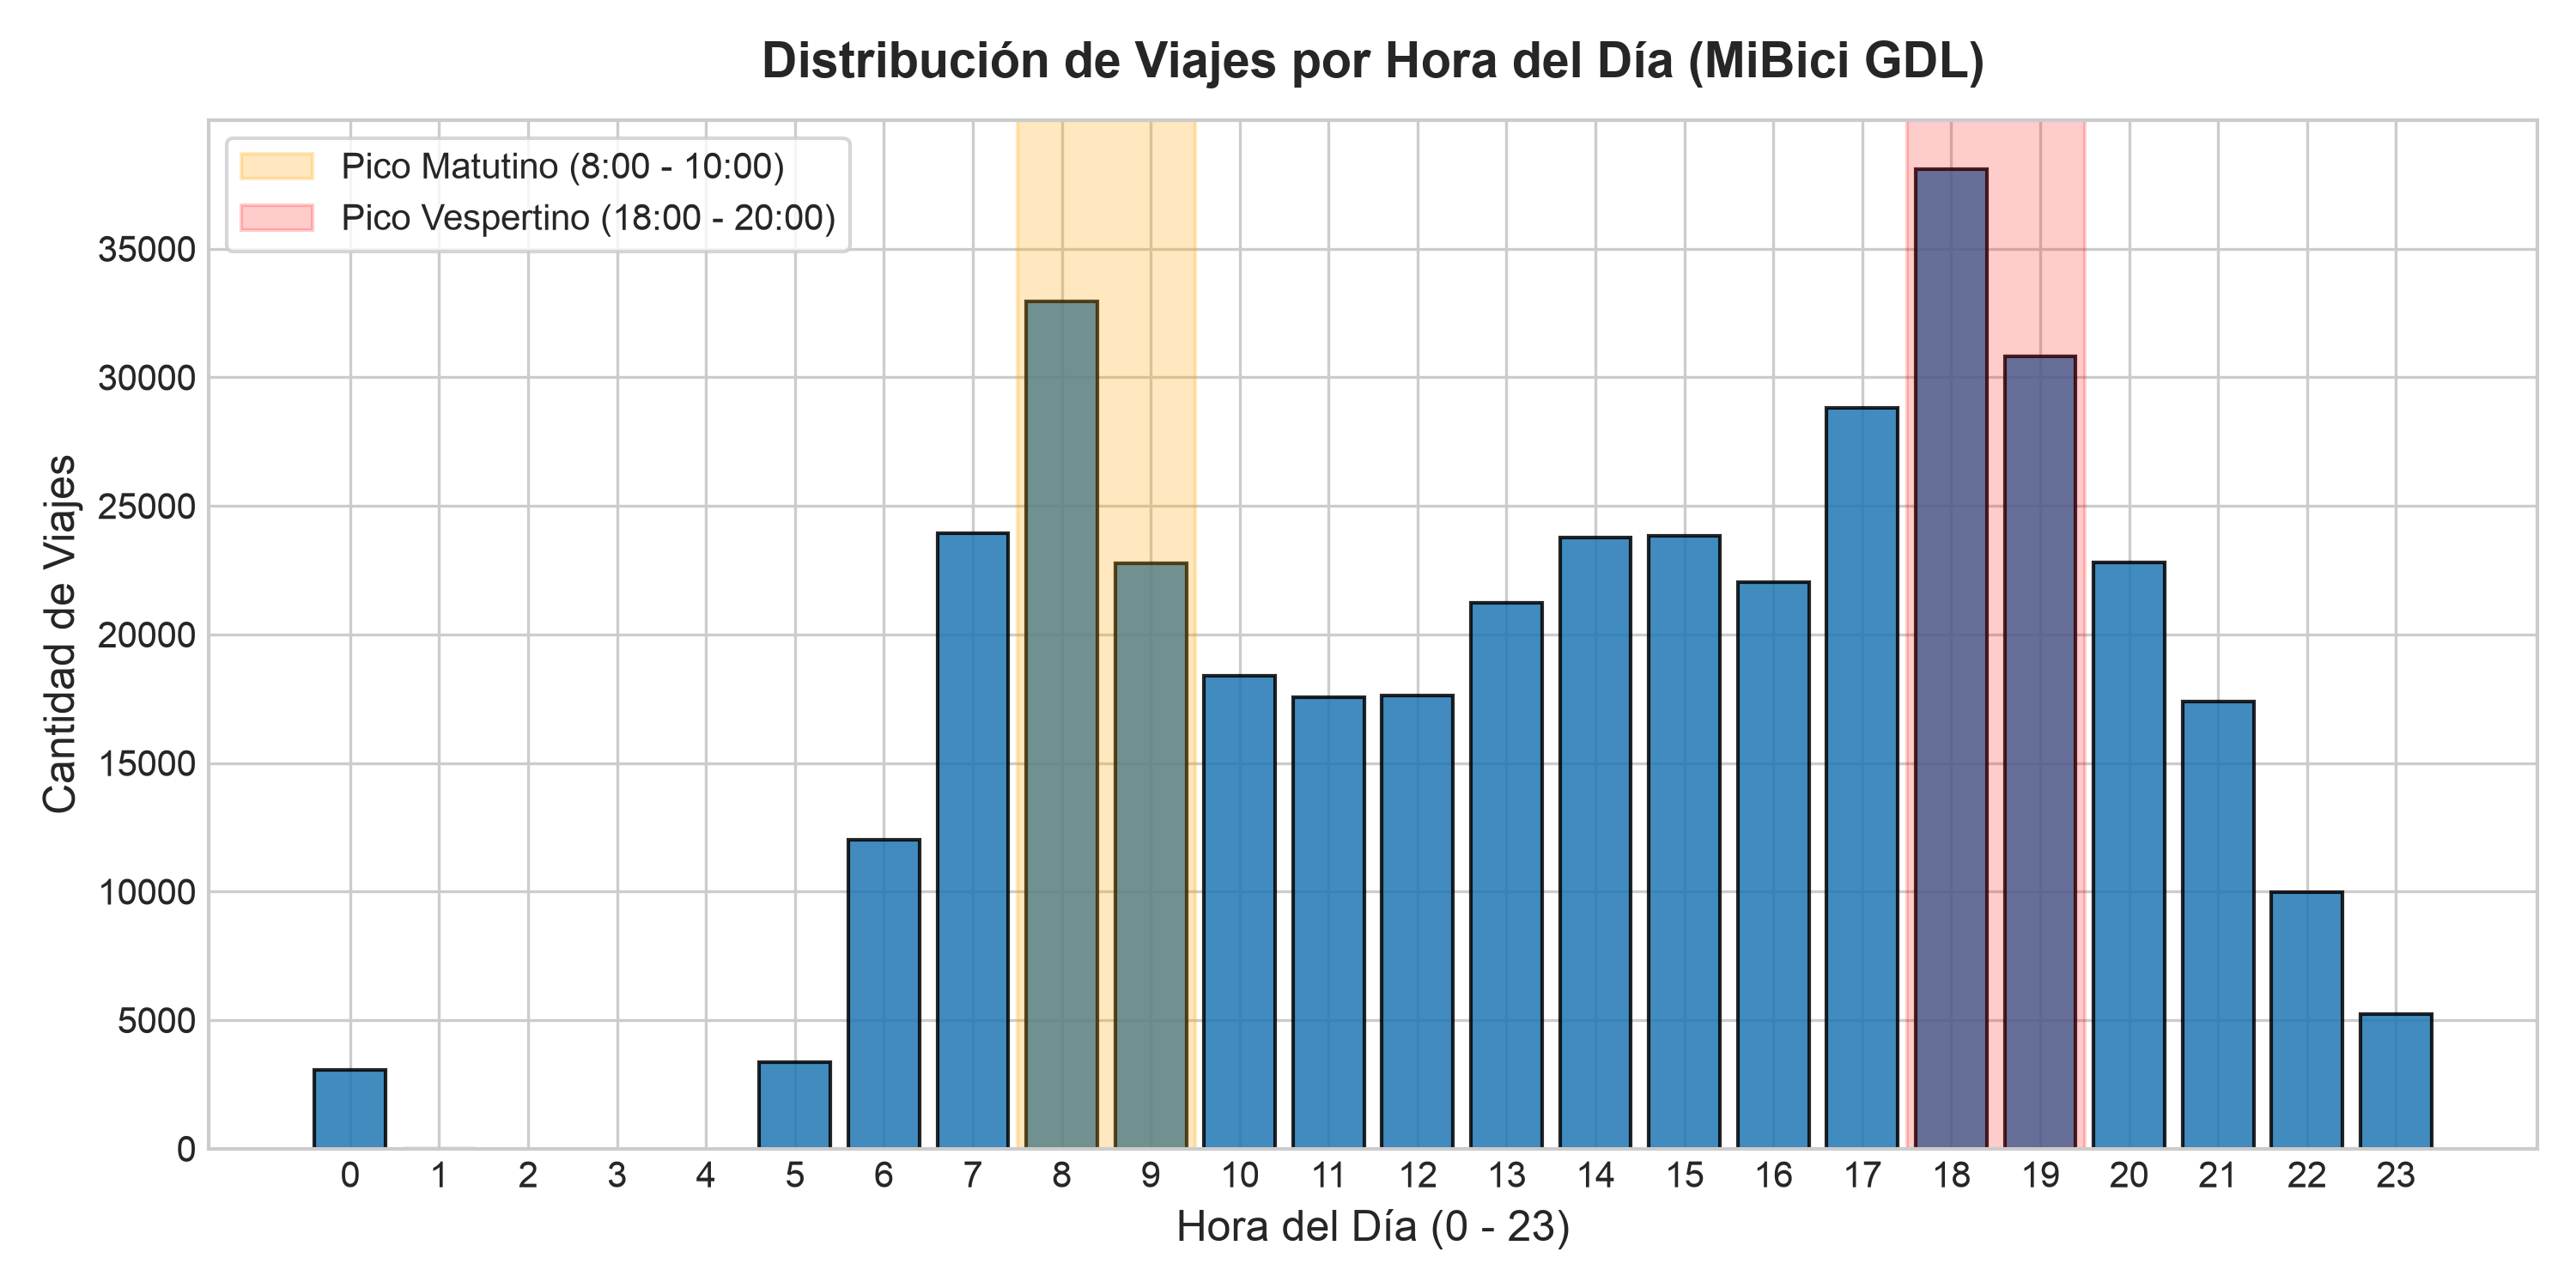

In [9]:
display(Image(filename='../reports/figures/01_distribucion_horaria.png', width=800))

### 5.2 Viajes por día de la semana

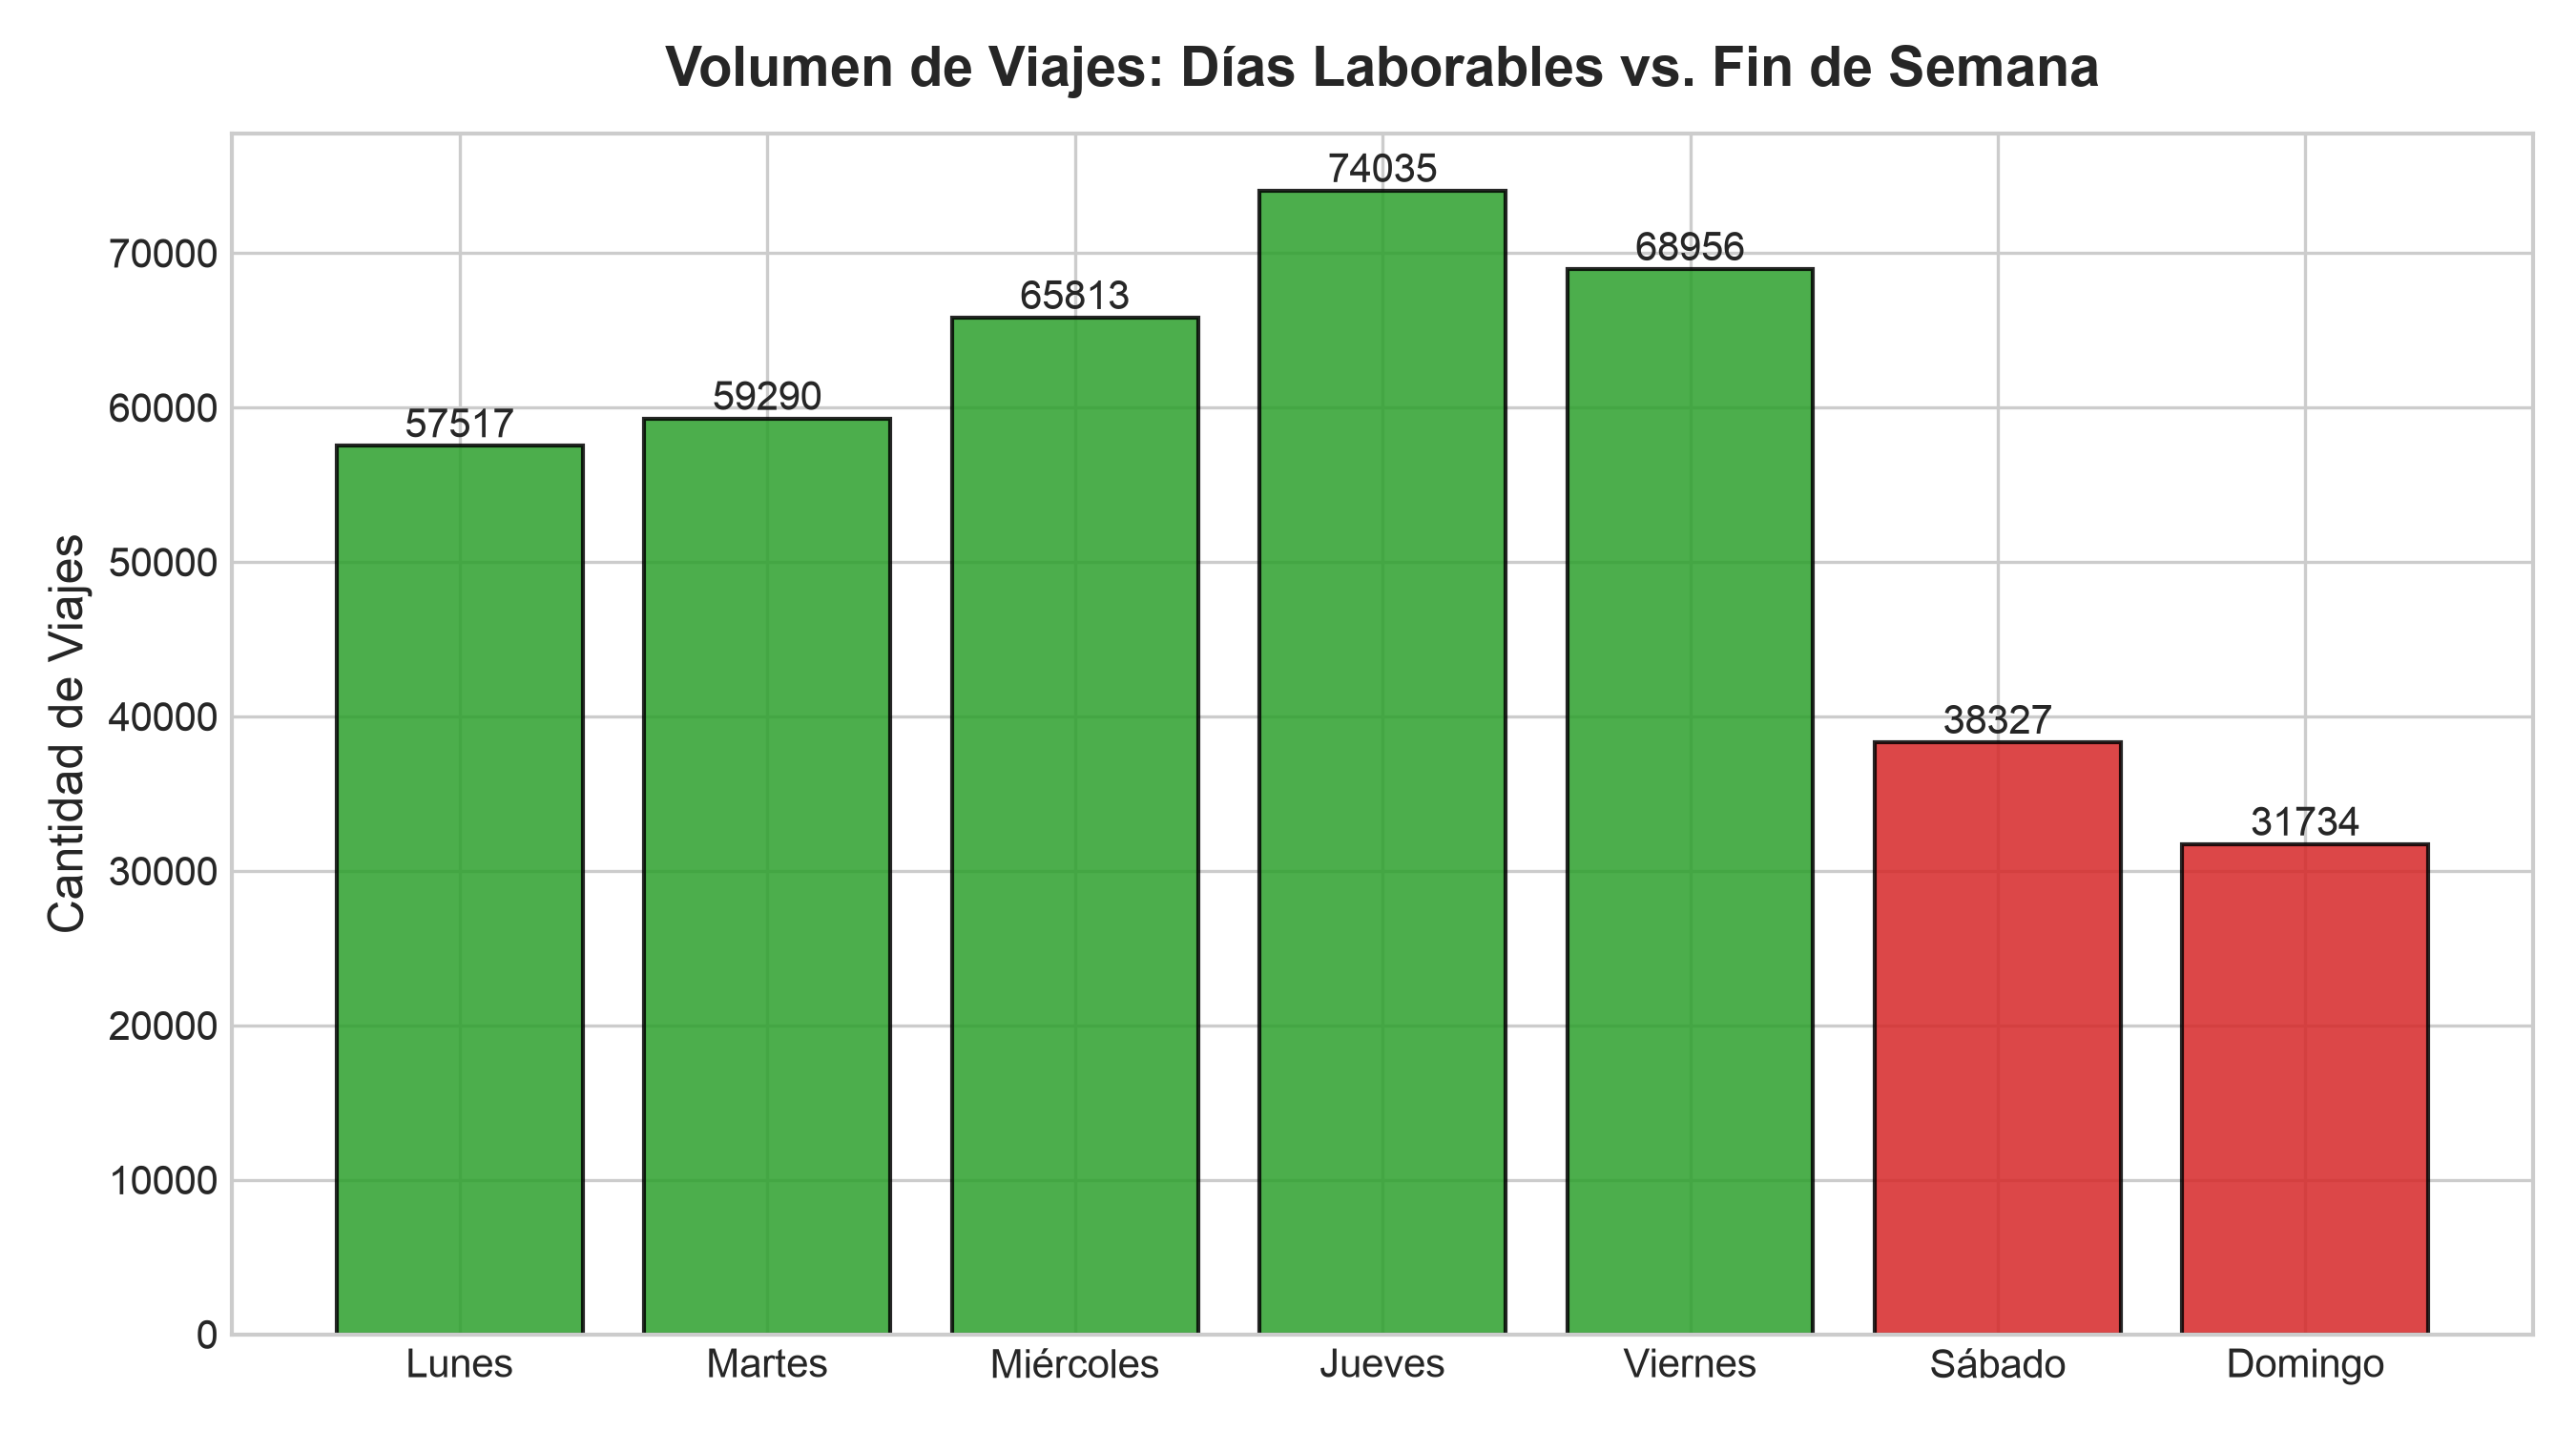

In [10]:
display(Image(filename='../reports/figures/02_viajes_dia_semana.png', width=800))

### 5.3 Top 10 estaciones con mayor demanda de origen

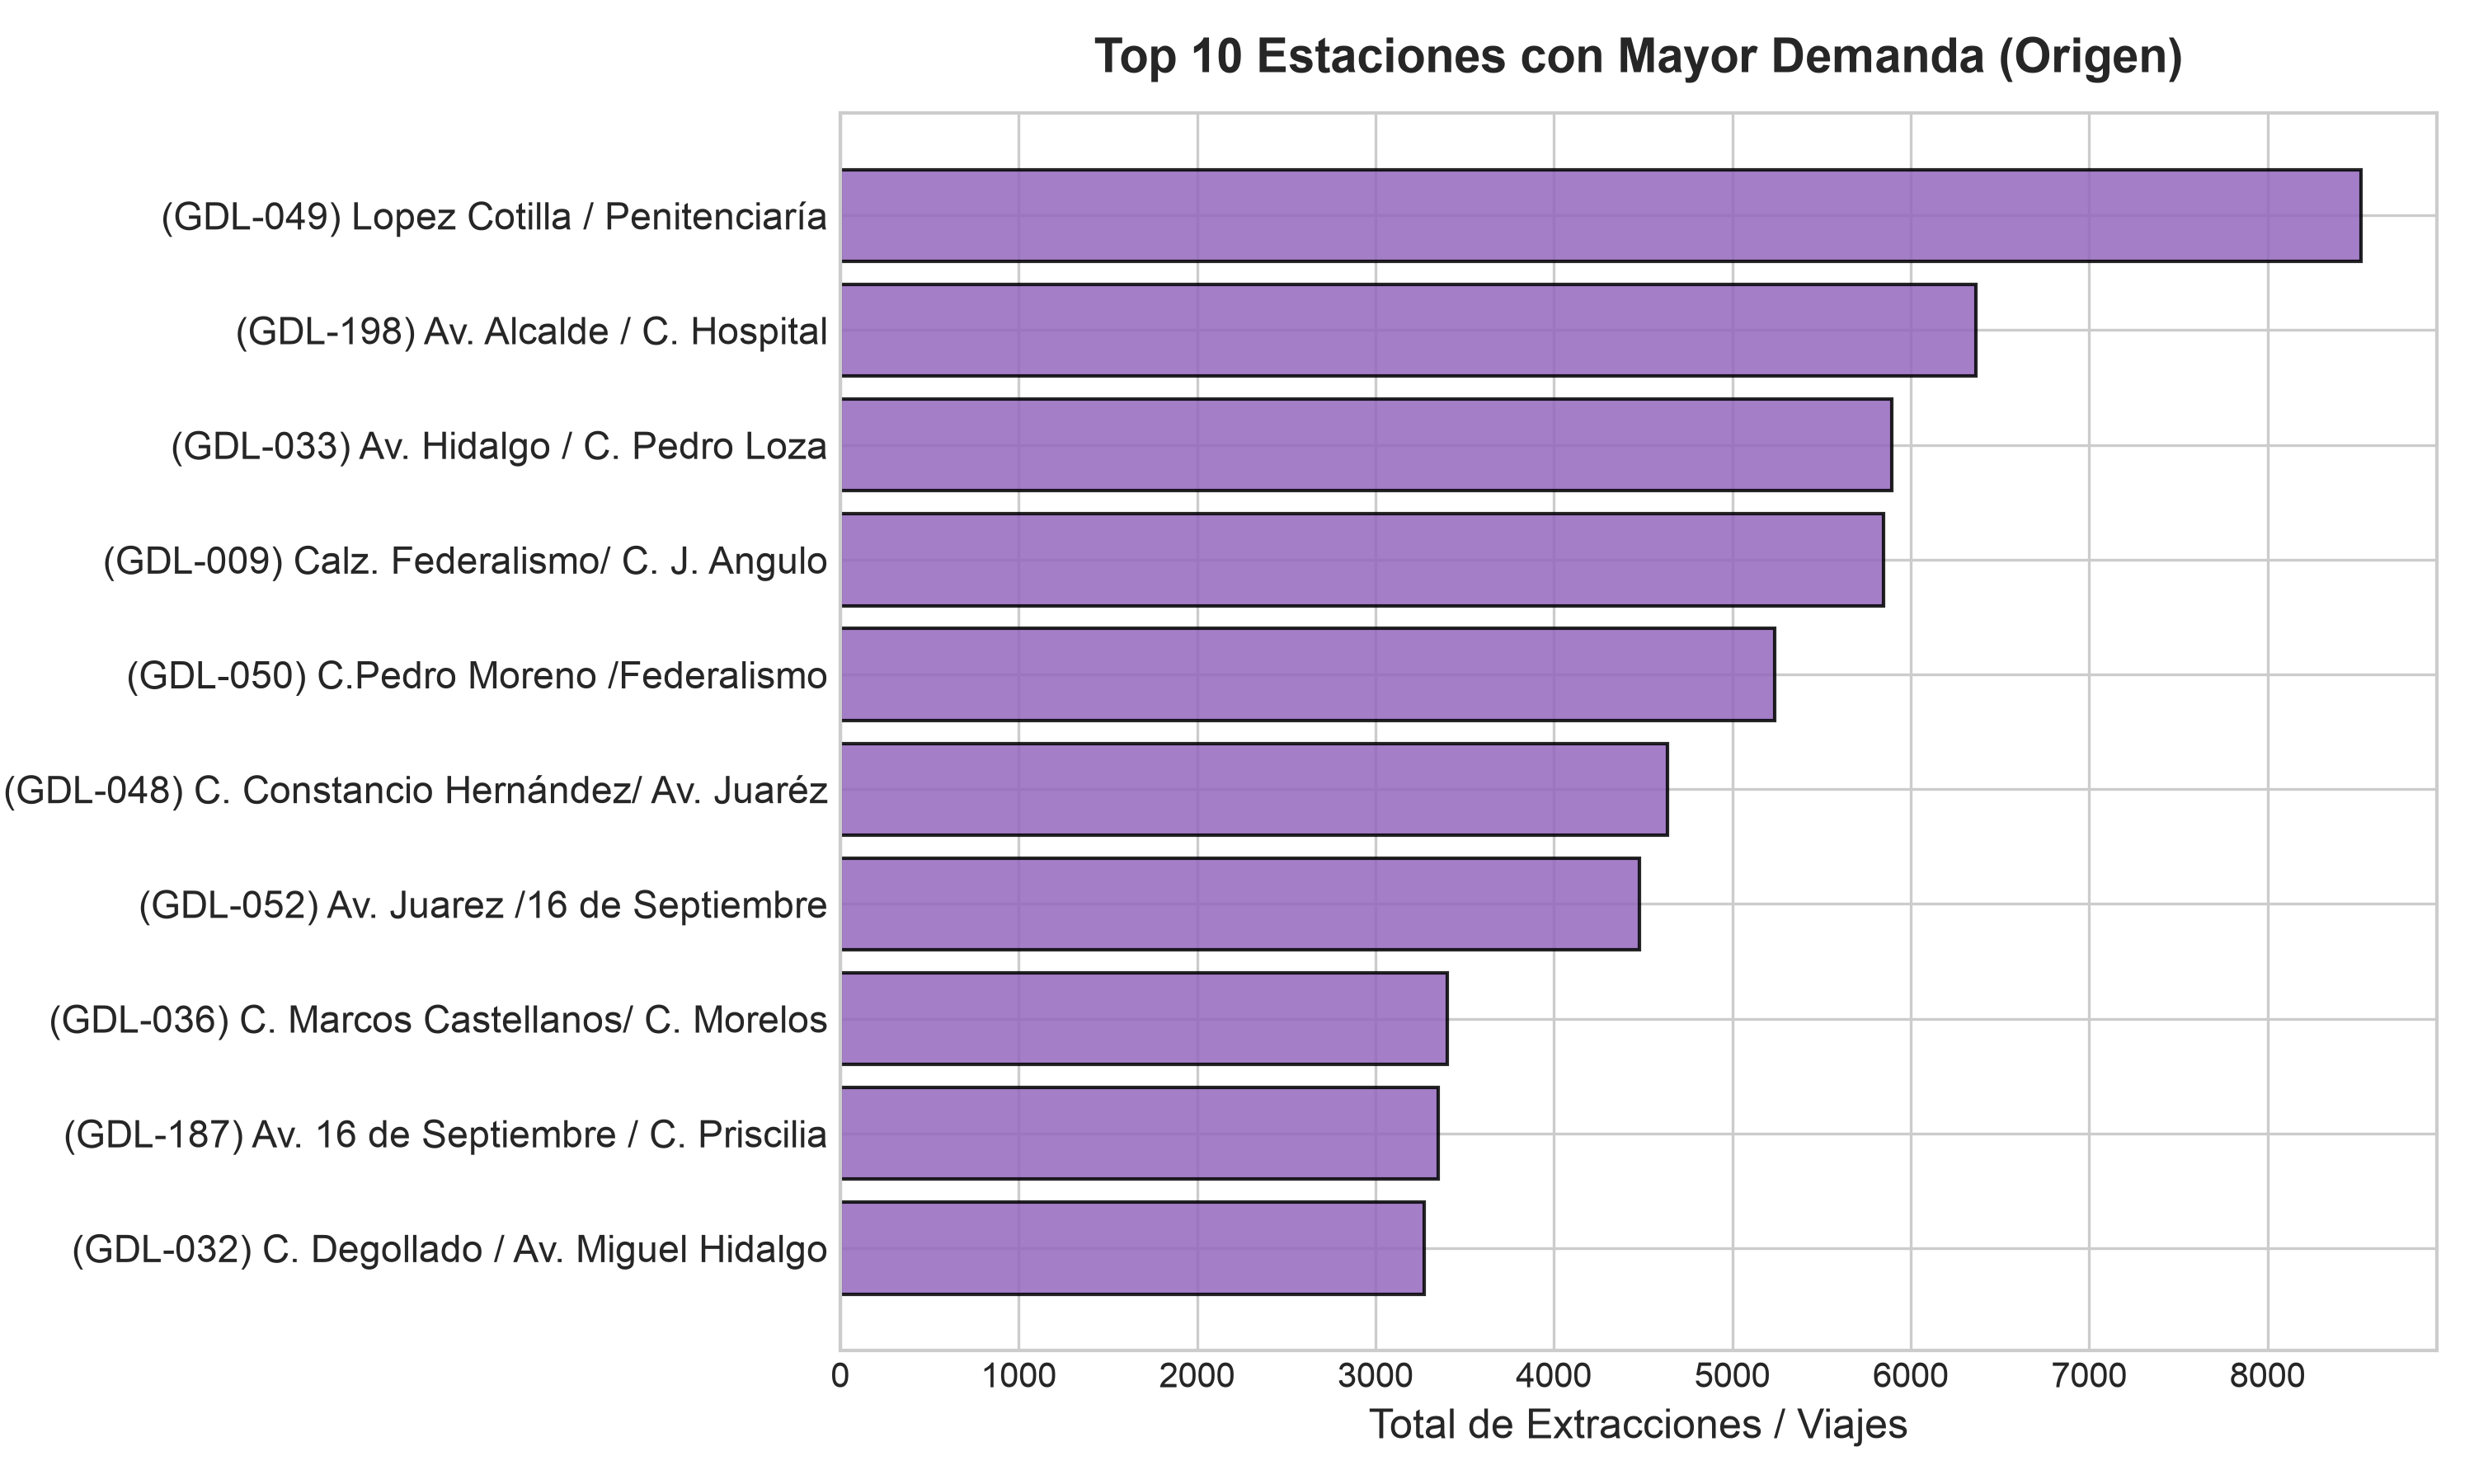

In [11]:
display(Image(filename='../reports/figures/03_top_estaciones_demanda.png', width=800))

### 5.4 Distribución de la duración de los viajes

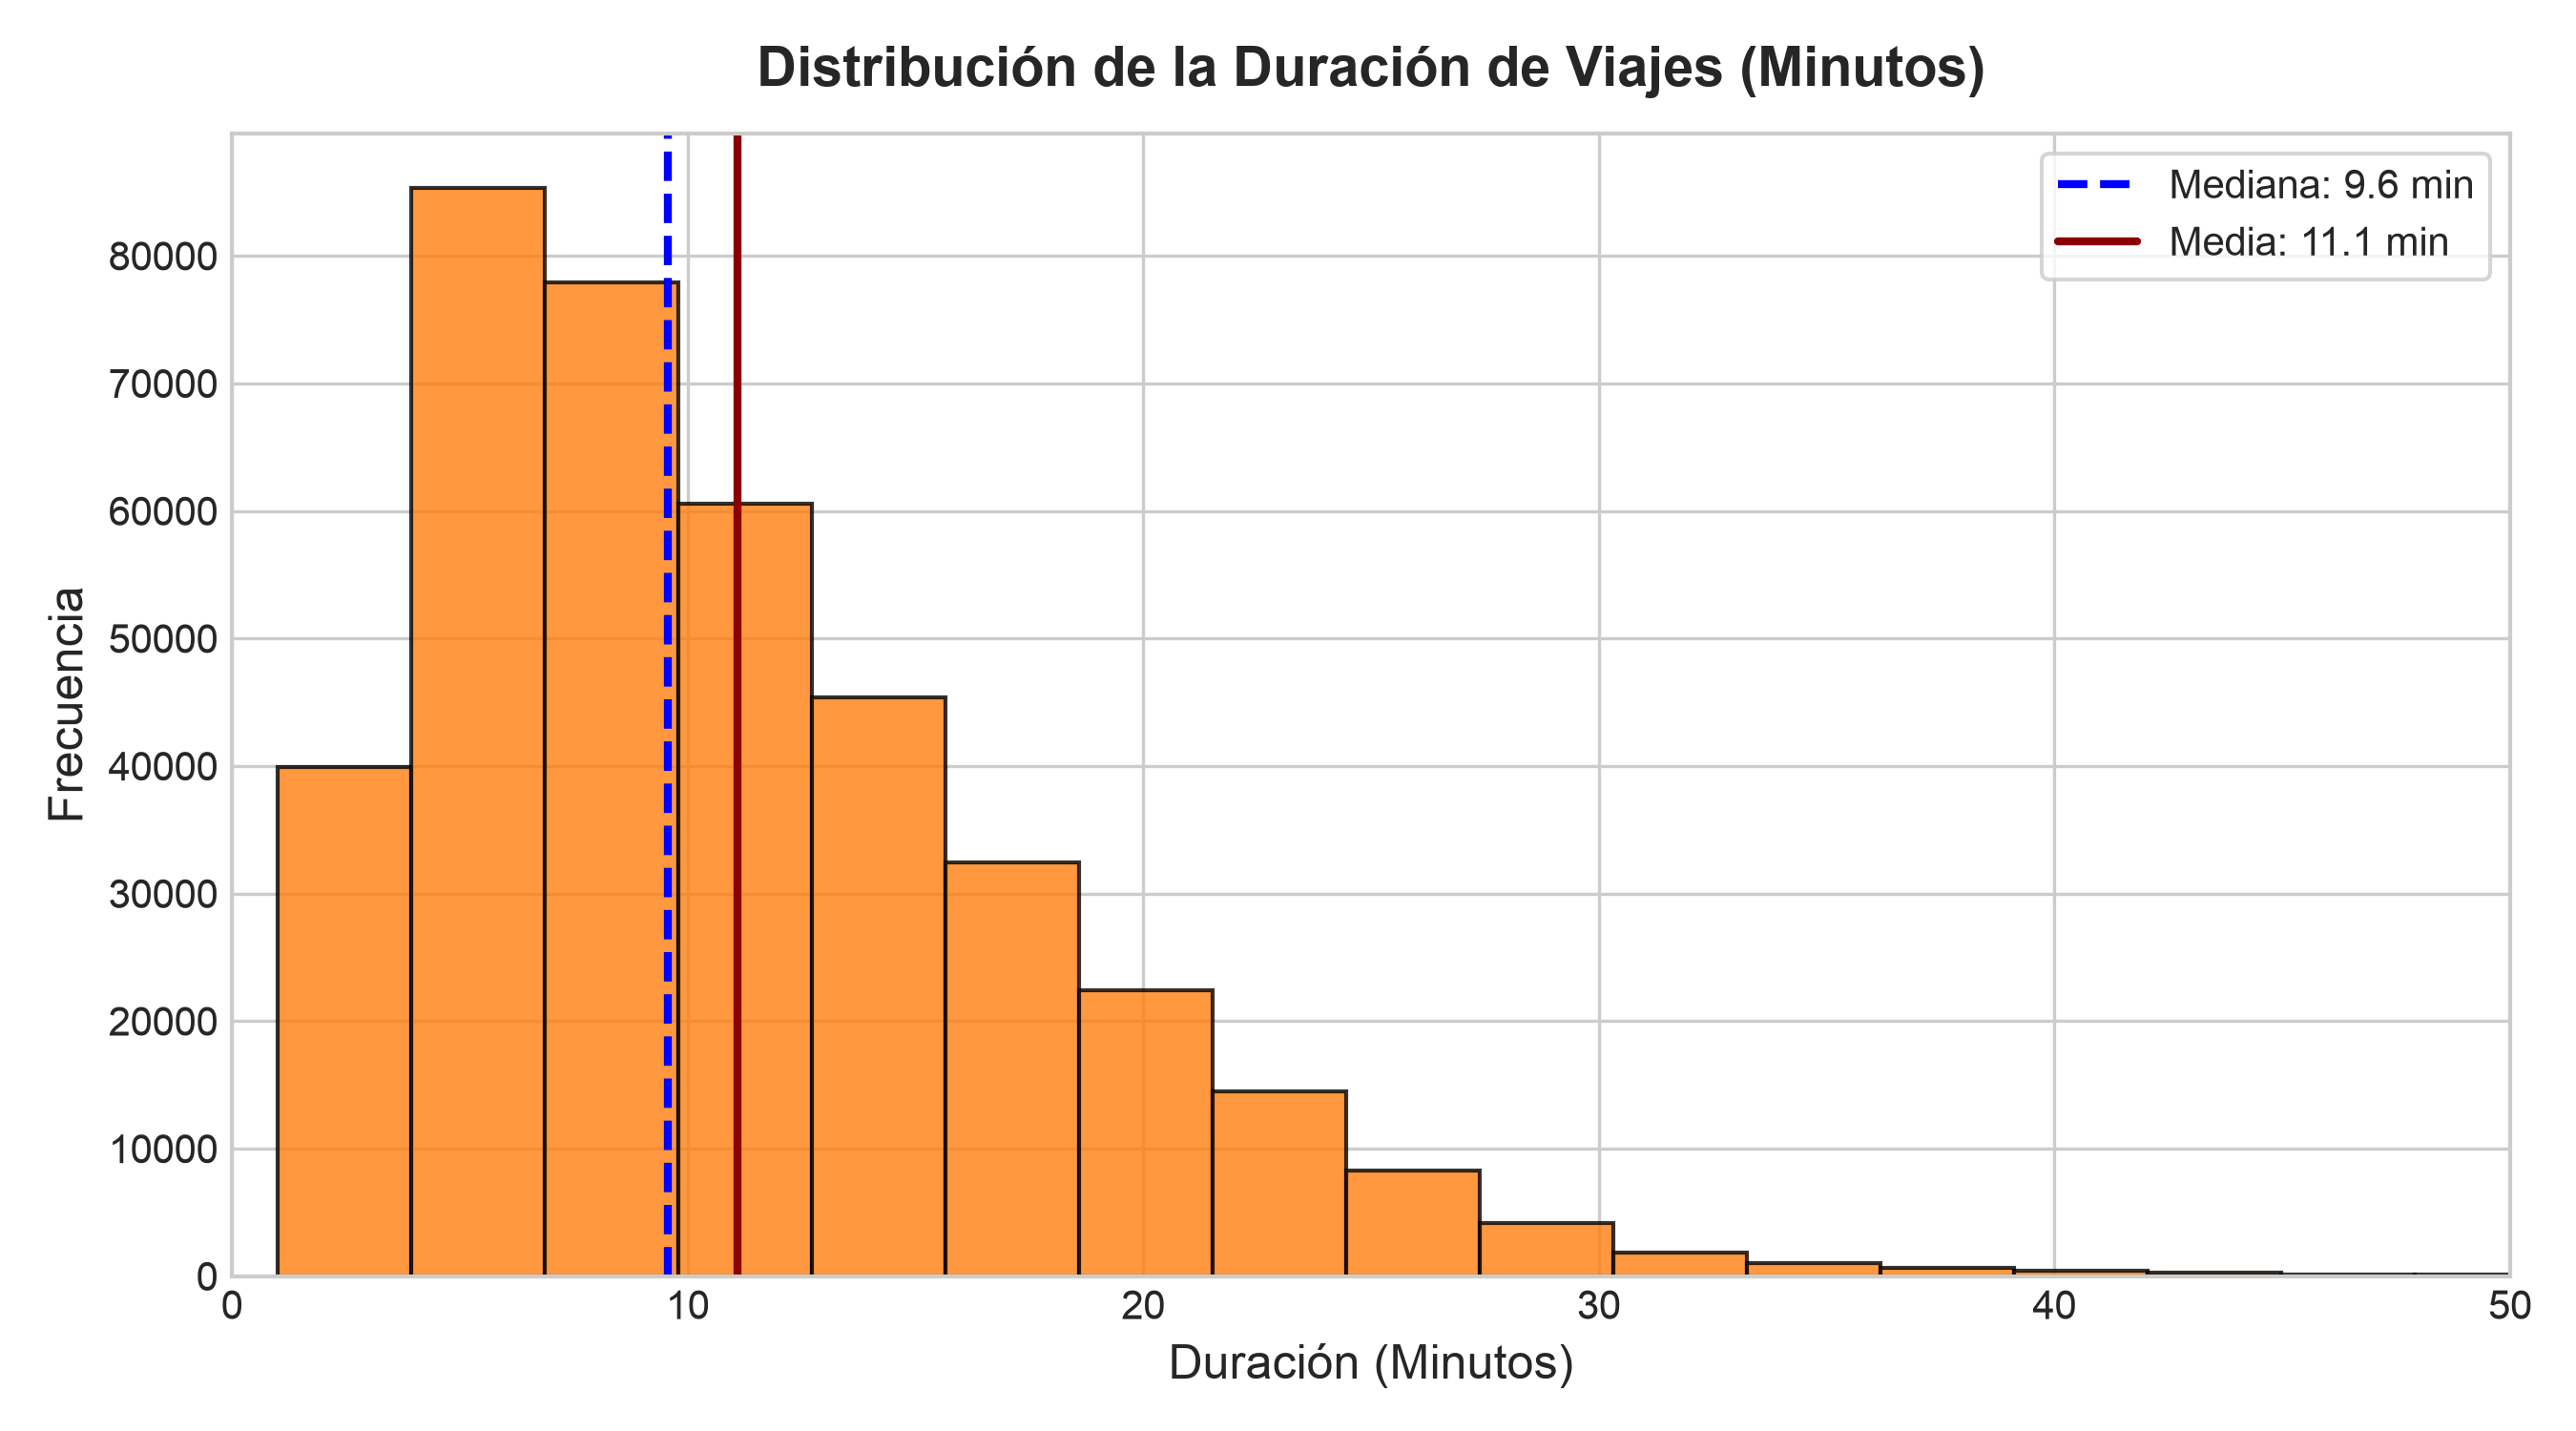

In [12]:
display(Image(filename='../reports/figures/04_distribucion_duracion.png', width=800))

### 5.5 Demografía de usuarios

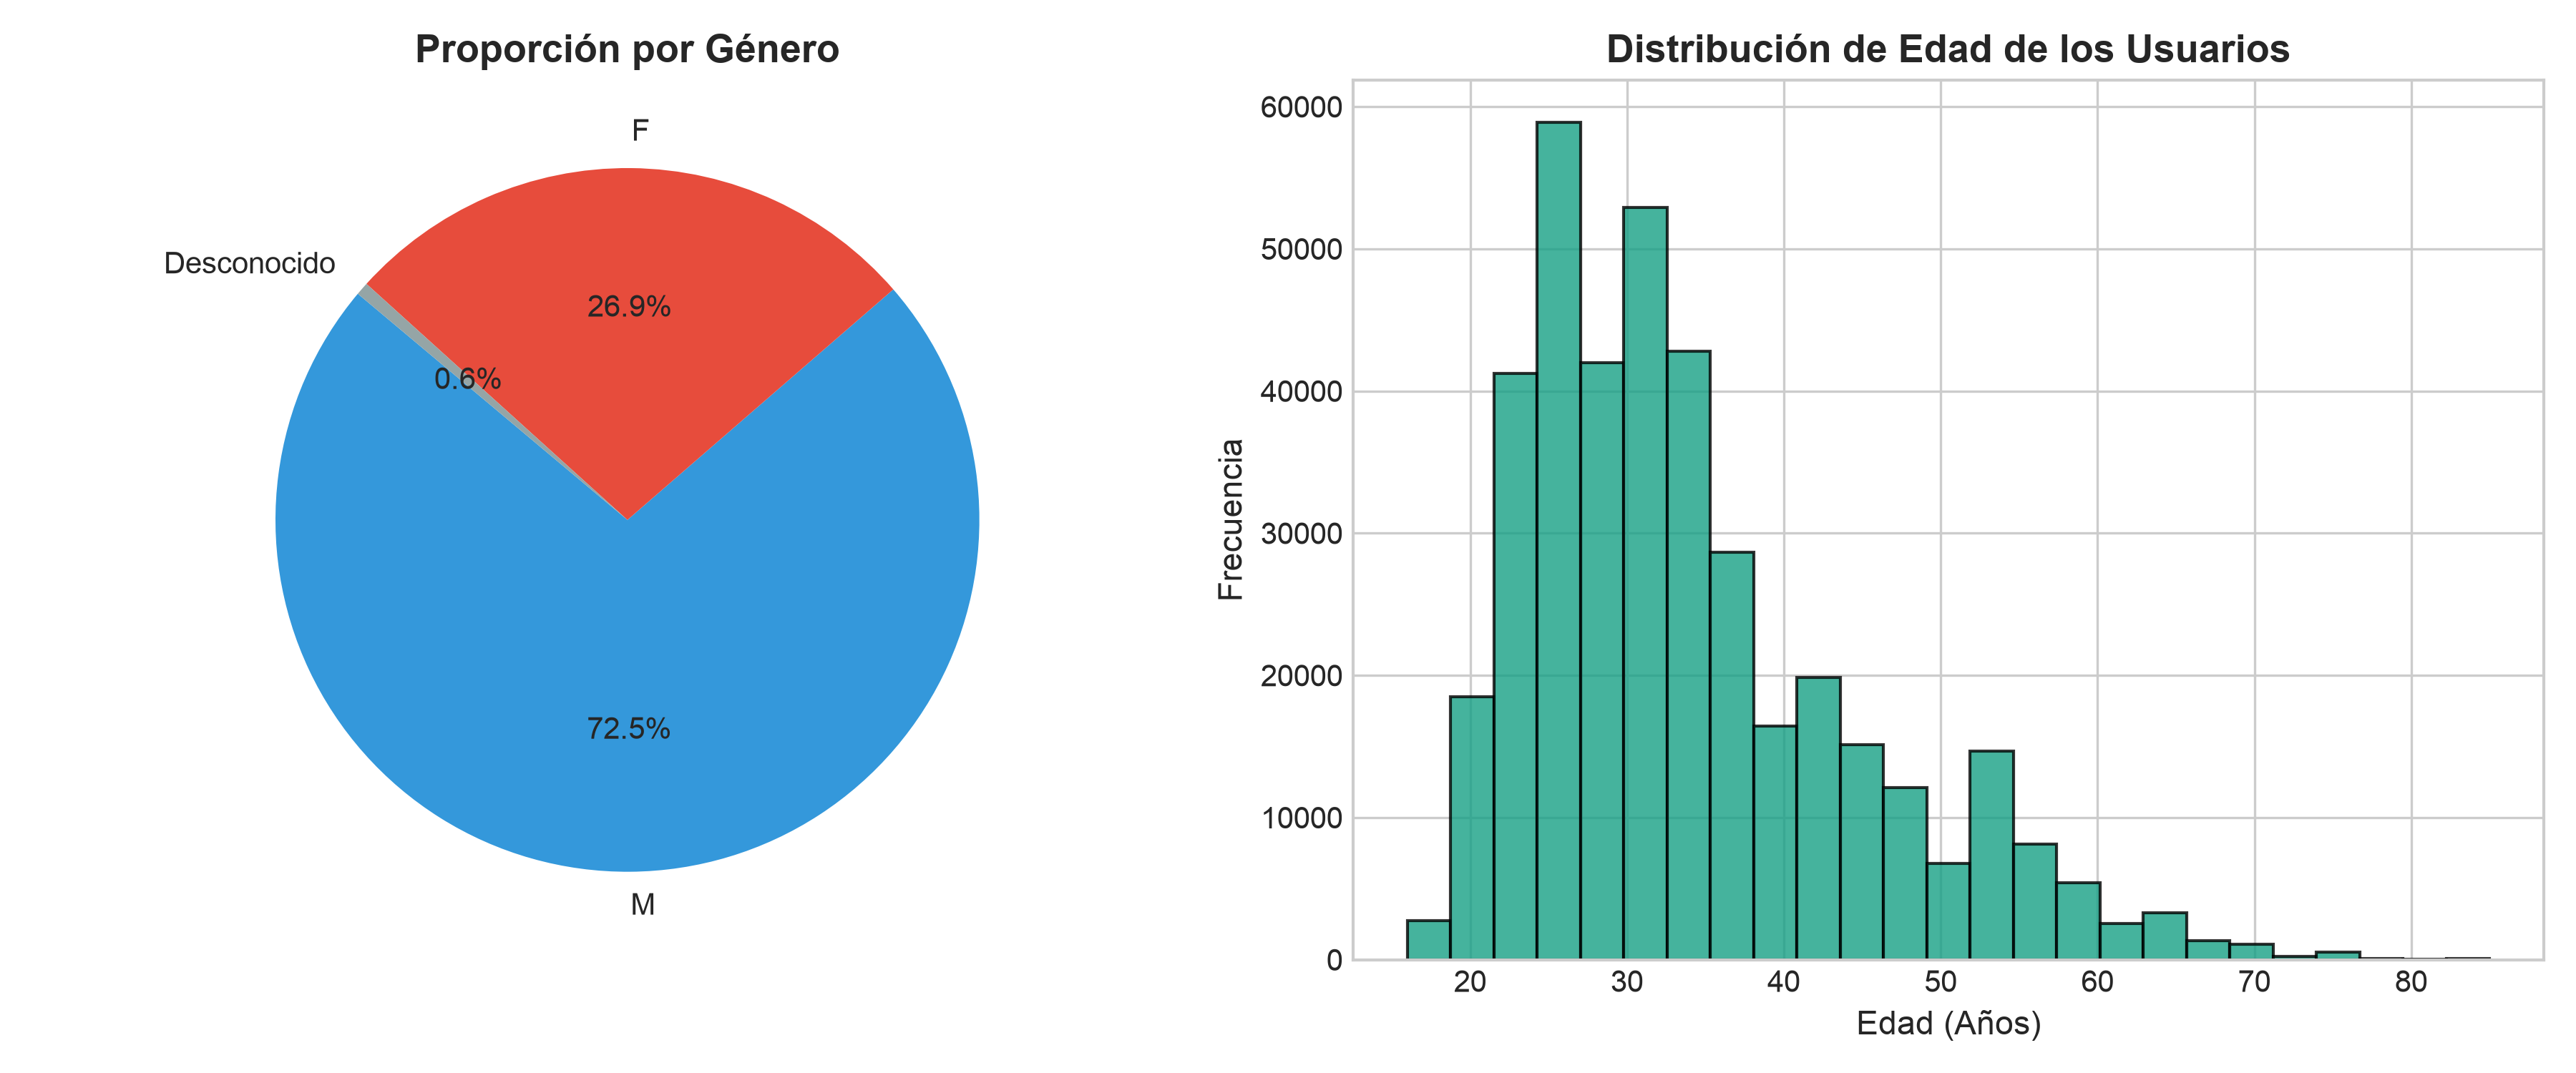

In [13]:
display(Image(filename='../reports/figures/05_demografia_usuarios.png', width=800))

## 6. Mapa de calor: día de la semana x hora del día

Cruza el patrón horario con el semanal para ver si los picos de entrada y salida laboral se mantienen el fin de semana.

In [14]:
dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
df_clean['dia_semana'] = df_clean['Inicio_del_viaje'].dt.dayofweek
df_clean['hora'] = df_clean['Inicio_del_viaje'].dt.hour

tabla_dia_hora = (
    df_clean.pivot_table(index='dia_semana', columns='hora', values='Viaje_Id', aggfunc='count', fill_value=0)
    .reindex(index=range(7), columns=range(24), fill_value=0)
)
tabla_dia_hora.index = dias

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(tabla_dia_hora, cmap='YlOrRd', linewidths=0.3, cbar_kws={'label': 'Viajes'}, ax=ax)
ax.set_title('Viajes por día de la semana y hora del día (mayo 2024)', fontsize=14, fontweight='bold')
ax.set_xlabel('Hora del día')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

horas_pico = tabla_dia_hora.loc[dias[:5]].sum().sort_values(ascending=False).head(3)
print('Horas con más viajes entre semana:')
print(horas_pico)

Horas con más viajes entre semana:
hora
18    34227
8     28835
19    26600
dtype: int64


/var/folders/qd/9s9z32s95cbf9gwx5qdc807w0000gn/T/ipykernel_10029/958052060.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_clean['dia_semana'] = df_clean['Inicio_del_viaje'].dt.dayofweek
/var/folders/qd/9s9z32s95cbf9gwx5qdc807w0000gn/T/ipykernel_10029/958052060.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 7. Matriz origen-destino de las 10 estaciones más demandadas

Permite identificar los flujos entre las estaciones centrales y medir qué fracción de los viajes que salen de ellas termina en otra estación del mismo grupo.

In [15]:
top10 = df_clean['Origen_Id'].value_counts().head(10).index.tolist()
nombres = (
    df_stations.set_index('id')['name']
    .str.replace(r'^\(GDL-\d+\)\s*', '', regex=True)
    .str.replace(r'^GDL-\d+\s*', '', regex=True)
)

od = df_clean[df_clean['Origen_Id'].isin(top10) & df_clean['Destino_Id'].isin(top10)]
matriz_od = (
    pd.crosstab(od['Origen_Id'], od['Destino_Id'])
    .reindex(index=top10, columns=top10, fill_value=0)
)
matriz_od.index = [nombres.get(i, str(i)) for i in matriz_od.index]
matriz_od.columns = [nombres.get(i, str(i)) for i in matriz_od.columns]

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(matriz_od, annot=True, fmt='d', cmap='Blues', linewidths=0.5, ax=ax)
ax.set_title('Matriz origen-destino entre las 10 estaciones más demandadas', fontsize=14, fontweight='bold')
ax.set_xlabel('Destino')
ax.set_ylabel('Origen')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

desde_top10 = df_clean[df_clean['Origen_Id'].isin(top10)]
print(f"Viajes que salen de las 10 estaciones principales: {len(desde_top10)} "
      f"({len(desde_top10) / len(df_clean) * 100:.1f}% del total limpio)")
print(f"De esos viajes, terminan en otra de las 10 estaciones principales: "
      f"{desde_top10['Destino_Id'].isin(top10).mean() * 100:.1f}%")

/var/folders/qd/9s9z32s95cbf9gwx5qdc807w0000gn/T/ipykernel_10029/1254570366.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Viajes que salen de las 10 estaciones principales: 51012 (12.9% del total limpio)
De esos viajes, terminan en otra de las 10 estaciones principales: 16.9%


## 8. Correlación de cada variable con `demand_count`

Se calcula la correlación de Pearson de cada variable de la matriz procesada con la variable objetivo. `month` se omite porque es constante (solo hay un mes de datos).

In [16]:
numericas = df_features.drop(columns=['fecha_hora']).select_dtypes(include='number')
numericas = numericas.loc[:, numericas.std() > 0]
correlaciones = numericas.corr()['demand_count'].drop('demand_count').sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
colores = ['#d62728' if v < 0 else '#2ca02c' for v in correlaciones.values]
ax.barh(correlaciones.index, correlaciones.values, color=colores, edgecolor='black', alpha=0.85)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Correlación de cada variable con demand_count', fontsize=14, fontweight='bold')
ax.set_xlabel('Coeficiente de correlación de Pearson')
for i, v in enumerate(correlaciones.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f'{v:.2f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9)
plt.tight_layout()
plt.show()

correlaciones.round(3).to_frame('correlacion_con_demand_count')

/var/folders/qd/9s9z32s95cbf9gwx5qdc807w0000gn/T/ipykernel_10029/2508357420.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,correlacion_con_demand_count
cos_hour,-0.240
Origen_Id,-0.236
sin_hour,-0.187
is_weekend,-0.107
day_of_week,-0.088
cos_dayofweek,-0.025
latitude,-0.008
longitude,0.027
sin_dayofweek,0.079
capacity,0.181


## 9. Distribución de la variable objetivo `demand_count`

La cuadrícula estación x hora incluye las horas sin extracciones (demanda cero), por lo que es importante medir qué tan frecuente es ese caso.

In [17]:
pct_ceros = (df_features['demand_count'] == 0).mean() * 100
print(f"Observaciones (estación x hora): {len(df_features):,}")
print(f"Media de demand_count: {df_features['demand_count'].mean():.3f}")
print(f"Máximo de demand_count: {df_features['demand_count'].max():.0f}")
print(f"Porcentaje de horas con demanda cero: {pct_ceros:.1f}%")

conteos = df_features['demand_count'].value_counts().sort_index()
conteos_visibles = conteos[conteos.index <= 20]

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(conteos_visibles.index, conteos_visibles.values, color='#1f77b4', edgecolor='black', alpha=0.85)
ax.set_title('Distribución de demand_count (extracciones por estación y hora)', fontsize=14, fontweight='bold')
ax.set_xlabel('demand_count (se muestran valores hasta 20)')
ax.set_ylabel('Número de observaciones')
ax.set_xticks(range(0, 21))
ax.annotate(f'{pct_ceros:.1f}% de ceros', xy=(0, conteos_visibles[0]), xytext=(4, conteos_visibles[0] * 0.9),
            arrowprops=dict(arrowstyle='->'), fontsize=11)
plt.tight_layout()
plt.show()

df_features['demand_count'].describe().round(3)

Observaciones (estación x hora): 267,840
Media de demand_count: 1.477
Máximo de demand_count: 76
Porcentaje de horas con demanda cero: 50.9%


/var/folders/qd/9s9z32s95cbf9gwx5qdc807w0000gn/T/ipykernel_10029/2930092410.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


count    267840.000
mean          1.477
std           2.559
min           0.000
25%           0.000
50%           0.000
75%           2.000
max          76.000
Name: demand_count, dtype: float64

## 10. Conclusiones del EDA

- **Patrón temporal marcado:** la demanda tiene dos picos claros entre semana, alrededor de las 8:00 (entrada laboral y escolar) y de las 18:00 (salida). El fin de semana el volumen baja y el patrón se aplana hacia el mediodía, lo que justifica las variables `hour`, `day_of_week`, `is_weekend` y sus transformaciones cíclicas.
- **Demanda concentrada en el centro:** las 10 estaciones con más extracciones se ubican en el Centro Histórico de Guadalajara (ejes Federalismo, Juárez, 16 de Septiembre, Hidalgo y Alcalde) y originan cerca del 13% de todos los viajes. Sin embargo, solo alrededor del 17% de esos viajes termina en otra estación del mismo grupo: las bicicletas se dispersan hacia el resto de la red, por lo que el rebalanceo debe reabastecer el centro desde las estaciones periféricas y no solo mover unidades entre estaciones centrales.
- **Viajes cortos:** la mediana de duración tras la limpieza es de aproximadamente 9.6 minutos y cerca del 99% de los viajes dura menos de 30 minutos, consistente con un uso de último kilómetro.
- **Limpieza con bajo impacto:** las reglas de calidad descartan cerca del 3.7% de los registros (sobre todo viajes menores a 1 minuto que corresponden a desanclajes fallidos), conservando 395,672 viajes válidos.
- **Variable objetivo con exceso de ceros:** al construir la cuadrícula de 360 estaciones activas x 744 horas, el 50.9% de las observaciones tiene demanda cero y la media es de 1.5 extracciones por hora. Se trata de un problema de conteos con sobredispersión, por lo que en la Fase 2 conviene comparar modelos para conteos (Poisson, Tweedie) y modelos basados en árboles frente a la regresión lineal.
- **Los rezagos son las variables más informativas:** `demand_lag_24h` y `demand_lag_1h` muestran la mayor correlación con `demand_count`, seguidas de `capacity` y las variables horarias, lo que confirma la relevancia de las variables históricas definidas en el ML Canvas.